# Recopilación de datos de NASA POWER

Este código accede a la API de NASA POWER para recopilar información de varias coordenadas a nivel global, permite graficar esta información en un plano, y exportar los datos recopilados a una base de datos en formato csv.

Se usan las siguientes librerías:

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import csv

## Recopilación de datos:
Se recopilan datos de la API de NASA POWER:

In [67]:
url_base = r"https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M&community=RE&longitude={longitude}&latitude={latitude}&start={inicio}&end={fin}&format=csv&header=false"

puntos=[]
for x in range(-80,81,5):
    for y in range(-160,181,5): puntos.append((x,y))
temperaturas = []

for (lat, long) in puntos:
    url = url_base.format(longitude=long, latitude=lat, inicio = 20041212, fin = 20041212)
    df = pd.read_csv(url)

    temperaturas.append(np.average(df['T2M']))

## Gráfico
Se genera usando matplotlib un diagrama de calor:

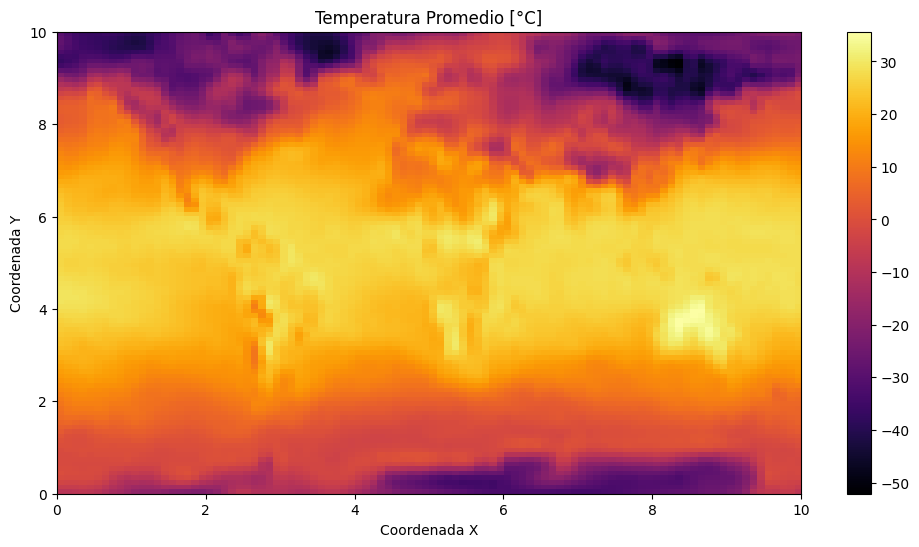

In [69]:
plt.rcParams['figure.figsize'] = [12,6]
plt.xlabel('Coordenada X')
plt.ylabel('Coordenada Y')
plt.title('Temperatura Promedio [°C]')

N = 30j
extent = (np.min([i[1] for i in puntos]),np.max([i[1] for i in puntos]),np.min([i[0] for i in puntos]),np.max([i[0] for i in puntos]))  
xs,ys = np.mgrid[extent[0]:extent[1]:N, extent[2]:extent[3]:N]    

grid_x, grid_y = np.mgrid[-160:180:100j, -80:80:100j]

grid_temp = griddata(([i[1] for i in puntos], [i[0] for i in puntos]), temperaturas, (grid_x, grid_y), method='cubic')

plt.imshow(grid_temp.T, extent=(0, 10, 0, 10), origin='lower', cmap='inferno', aspect='auto')
plt.colorbar()

## 